# SepHAR-Net — Reproducibility Notebook

Reproduces all experiments, tables, and figures in the paper **"SepHAR-Net: A Lightweight Separable-Convolution Network for Efficient Human Activity Recognition."**

Contents: data loading for two public datasets (UCI HAR, MotionSense); all model architectures (SepHAR-Net, six standard baselines, and the TinyHAR / Transformer lightweight baselines); model-efficiency metrics; the **primary** leave-one-subject-out (LOSO) evaluation with subject-level statistical testing on both datasets; the **secondary** fixed-split five-seed stability analysis; and Figures 1–6.

**Environment:** Python 3 with TensorFlow/Keras, scikit-learn, SciPy, statsmodels, matplotlib (developed on Google Colab, NVIDIA T4 GPU).

**Runtime:** the LOSO evaluations are heavy (several hours each) and are cached to JSON after every fold, so the runs are resumable — re-running a cell skips completed folds. The cell outputs saved in this notebook are from the run reported in the paper.

## 1. Datasets

### 1.1 Upload UCI HAR dataset
Upload `UCI HAR Dataset.zip` from the UCI Machine Learning Repository (doi:10.24432/C54S4K).

In [ ]:
# Upload "UCI HAR Dataset.zip" from your browser
from google.colab import files
import zipfile, os

uploaded = files.upload()                 # pick UCI HAR Dataset.zip
zip_name = next(iter(uploaded))
with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall()
print("Extracted:", zip_name)

Saving UCI HAR Dataset.zip to UCI HAR Dataset.zip
Extracted: UCI HAR Dataset.zip


### 1.2 Setup, seeds, and dataset location
Imports and seeds all random-number generators for reproducibility, then locates the extracted dataset.

In [ ]:
import os, glob, random
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATASET_PATH = "UCI HAR Dataset"
if not os.path.exists(os.path.join(DATASET_PATH, "train", "Inertial Signals")):
    hits = glob.glob("**/train/Inertial Signals", recursive=True)
    DATASET_PATH = os.path.dirname(os.path.dirname(hits[0])) if hits else DATASET_PATH

assert os.path.exists(os.path.join(DATASET_PATH, "train", "Inertial Signals")), \
    f"Could not find dataset under '{DATASET_PATH}'."
print("Dataset root:", DATASET_PATH)
print("TensorFlow  :", tf.__version__)

Dataset root: UCI HAR Dataset
TensorFlow  : 2.21.0


### 1.3 Load UCI HAR with a subject-independent split
Uses the six body-motion channels and the official subject-independent split, holding out four training subjects as a subject-disjoint validation set. Leakage is checked programmatically.

In [ ]:
SIGNALS = ["body_acc_x", "body_acc_y", "body_acc_z",
           "body_gyro_x", "body_gyro_y", "body_gyro_z"]   # 6 IMU channels

def load_split(split):
    sig_dir = os.path.join(DATASET_PATH, split, "Inertial Signals")
    data = [pd.read_csv(os.path.join(sig_dir, f"{s}_{split}.txt"),
                        sep=r"\s+", header=None).values
            for s in SIGNALS]
    X = np.stack(data, axis=-1).astype("float32")                      # (N,128,6)
    y = pd.read_csv(os.path.join(DATASET_PATH, split, f"y_{split}.txt"),
                    header=None).values.flatten().astype("int32") - 1  # 0..5
    subj = pd.read_csv(os.path.join(DATASET_PATH, split, f"subject_{split}.txt"),
                       header=None).values.flatten()
    return X, y, subj

X_train_full, y_train_full, subj_train = load_split("train")
X_test,       y_test,       subj_test  = load_split("test")

rng = np.random.RandomState(SEED)
uniq_subj = np.unique(subj_train)
n_val_subj = max(1, round(0.20 * len(uniq_subj)))
val_subjects = np.sort(rng.choice(uniq_subj, size=n_val_subj, replace=False))
val_mask = np.isin(subj_train, val_subjects)

X_val, y_val = X_train_full[val_mask],  y_train_full[val_mask]
X_tr,  y_tr  = X_train_full[~val_mask], y_train_full[~val_mask]

NUM_CLASSES = 6
INPUT_SHAPE = X_tr.shape[1:]
ACTIVITIES  = {0:"WALKING",1:"WALKING_UPSTAIRS",2:"WALKING_DOWNSTAIRS",
               3:"SITTING",4:"STANDING",5:"LAYING"}

print("Train subjects:", np.setdiff1d(uniq_subj, val_subjects))
print("Val subjects  :", val_subjects)
print("Test subjects :", np.unique(subj_test))
print("X_tr", X_tr.shape, "| X_val", X_val.shape, "| X_test", X_test.shape)
assert set(np.unique(subj_train[~val_mask])).isdisjoint(set(val_subjects)), "train/val overlap!"
assert set(np.unique(subj_train)).isdisjoint(set(np.unique(subj_test))),   "train/test overlap!"
print("No subject overlap across train / val / test  ->  OK")

Train subjects: [ 5  6  7  8 11 14 15 16 17 19 21 22 23 26 28 29 30]
Val subjects  : [ 1  3 25 27]
Test subjects : [ 2  4  9 10 12 13 18 20 24]
X_tr (5879, 128, 6) | X_val (1473, 128, 6) | X_test (2947, 128, 6)
No subject overlap across train / val / test  ->  OK


### 1.4 MotionSense (second dataset)
Downloaded automatically; linear acceleration and angular velocity (six channels), windowed identically to UCI HAR (128 samples, 50% overlap).

In [ ]:
# Point 5 — MotionSense (second dataset): download + extract
import os, zipfile, urllib.request
if not os.path.isdir("A_DeviceMotion_data"):
    url = "https://github.com/mmalekzadeh/motion-sense/raw/master/data/A_DeviceMotion_data.zip"
    print("Downloading MotionSense (~73 MB) ...")
    urllib.request.urlretrieve(url, "A_DeviceMotion_data.zip")
    assert os.path.getsize("A_DeviceMotion_data.zip") > 1_000_000, "download failed"
    with zipfile.ZipFile("A_DeviceMotion_data.zip") as z:
        z.extractall()
    print("Extracted.")
trials = [d for d in os.listdir("A_DeviceMotion_data")
          if os.path.isdir(os.path.join("A_DeviceMotion_data", d))]
print("Trial folders:", len(trials), "->", sorted(trials))


Extracted.
Trial folders: 15 -> ['dws_1', 'dws_11', 'dws_2', 'jog_16', 'jog_9', 'sit_13', 'sit_5', 'std_14', 'std_6', 'ups_12', 'ups_3', 'ups_4', 'wlk_15', 'wlk_7', 'wlk_8']


In [ ]:
import numpy as np, pandas as pd, glob, re
MS_DIR = "A_DeviceMotion_data"
ACT2ID = {"dws":0,"ups":1,"wlk":2,"jog":3,"sit":4,"std":5}
MS_ACTIVITIES = {0:"downstairs",1:"upstairs",2:"walking",3:"jogging",4:"sitting",5:"standing"}
COLS = ["userAcceleration.x","userAcceleration.y","userAcceleration.z",
        "rotationRate.x","rotationRate.y","rotationRate.z"]
WIN, STEP = 128, 64
Xw, yw, sw = [], [], []
for trial in sorted(os.listdir(MS_DIR)):
    tp = os.path.join(MS_DIR, trial)
    if not os.path.isdir(tp): continue
    act = trial.split("_")[0]
    if act not in ACT2ID: continue
    lab = ACT2ID[act]
    for csv in glob.glob(os.path.join(tp, "sub_*.csv")):
        sid = int(re.findall(r"sub_(\d+)", os.path.basename(csv))[0])
        sig = pd.read_csv(csv)[COLS].values.astype("float32")
        for st in range(0, len(sig)-WIN+1, STEP):
            Xw.append(sig[st:st+WIN]); yw.append(lab); sw.append(sid)
X_ms, y_ms, subj_ms = np.stack(Xw).astype("float32"), np.array(yw,"int32"), np.array(sw)
ms_subjects = np.unique(subj_ms)
print("MotionSense windows:", X_ms.shape, "| subjects:", len(ms_subjects))
print("class counts:", {MS_ACTIVITIES[i]:int(c) for i,c in enumerate(np.bincount(y_ms))})
assert X_ms.shape[1:] == (128, 6) and not np.isnan(X_ms).any()
print("Expect ~21,539 windows / 24 subjects (matches my validation).")


MotionSense windows: (21539, 128, 6) | subjects: 24
class counts: {'downstairs': 1952, 'upstairs': 2350, 'walking': 5275, 'jogging': 2025, 'sitting': 5221, 'standing': 4716}
Expect ~21,539 windows / 24 subjects (matches my validation).


## 2. Models

### 2.1 Training harness
A single pipeline trains and evaluates every architecture identically. Early stopping and learning-rate scheduling monitor **validation accuracy** (not loss), which avoids returning under-trained recurrent models.

In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

ALL_RESULTS = {}
ALL_PREDS   = {}

def reset_seeds(seed):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

def run_experiment(build_fn, name, seed=42, epochs=100, batch_size=64,
                   lr=1e-3, patience=15, verbose=0):
    reset_seeds(seed)
    tf.keras.backend.clear_session()

    model = build_fn(INPUT_SHAPE, NUM_CLASSES)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    n_params = model.count_params()

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                         patience=patience, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", mode="max",
                                             factor=0.5, patience=6, min_lr=1e-5, verbose=0),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=batch_size,
                     callbacks=callbacks, verbose=verbose)
    train_time = time.time() - t0

    _ = model.predict(X_test[:64], verbose=0)                 # warm-up
    t0 = time.time()
    y_prob = model.predict(X_test, verbose=0)
    infer_ms = (time.time() - t0) / len(X_test) * 1000.0
    y_pred = y_prob.argmax(1)

    acc = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred,
                                                  average="weighted", zero_division=0)
    res = dict(name=name, seed=seed, accuracy=acc, precision=p, recall=r, f1=f1,
               params=n_params, train_time_s=train_time, infer_ms_per_sample=infer_ms,
               epochs_run=len(hist.history["loss"]))
    ALL_RESULTS.setdefault(name, []).append(res)
    ALL_PREDS[(name, seed)] = y_pred
    print(f"[{name} | seed {seed}] acc={acc*100:.2f}%  f1={f1*100:.2f}%  "
          f"params={n_params:,}  train={train_time:.1f}s  infer={infer_ms:.4f} ms  "
          f"epochs={res['epochs_run']}")
    return res

### 2.2 Baseline architectures
Six standard baselines: CNN, LSTM, BiLSTM, GRU, CNN-LSTM, CNN-GRU.

In [ ]:
from tensorflow.keras import layers, Model, Input

def build_cnn(inp_shape, n):
    i = Input(inp_shape)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(i)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x); x = layers.Dropout(0.3)(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="CNN")

def build_lstm(inp_shape, n):
    i = Input(inp_shape)
    x = layers.LSTM(64, return_sequences=True)(i); x = layers.Dropout(0.3)(x)
    x = layers.LSTM(64)(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="LSTM")

def build_bilstm(inp_shape, n):
    i = Input(inp_shape)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(i); x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(32))(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="BiLSTM")

def build_gru(inp_shape, n):
    i = Input(inp_shape)
    x = layers.GRU(64, return_sequences=True)(i); x = layers.Dropout(0.3)(x)
    x = layers.GRU(64)(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="GRU")

def build_cnn_lstm(inp_shape, n):
    i = Input(inp_shape)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(i)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    x = layers.LSTM(64)(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="CNN_LSTM")

def build_cnn_gru(inp_shape, n):
    i = Input(inp_shape)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(i)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    x = layers.GRU(64)(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="CNN_GRU")

BASELINES = {"CNN": build_cnn, "LSTM": build_lstm, "BiLSTM": build_bilstm,
             "GRU": build_gru, "CNN_LSTM": build_cnn_lstm, "CNN_GRU": build_cnn_gru}
print("Baseline builders ready:", list(BASELINES))

Baseline builders ready: ['CNN', 'LSTM', 'BiLSTM', 'GRU', 'CNN_LSTM', 'CNN_GRU']


### 2.3 SepHAR-Net (proposed)
Multi-scale depthwise-separable stem → separable residual block (48 filters) with a 1×1 pointwise shortcut → bidirectional GRU (24 units per direction) → compact classification head. **24,288 parameters.**

In [ ]:
def build_imuclanet_lite(inp_shape, n):
    i = Input(inp_shape)
    # multi-scale depthwise-separable stem
    b = [layers.SeparableConv1D(24, k, padding="same", activation="relu")(i)
         for k in (3, 5, 7)]
    x = layers.Concatenate()(b)                        # (128, 72)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    # separable residual stage
    sc = layers.Conv1D(48, 1, padding="same")(x)       # pointwise projection
    y = layers.SeparableConv1D(48, 3, padding="same", activation="relu")(x)
    y = layers.BatchNormalization()(y)
    y = layers.SeparableConv1D(48, 3, padding="same")(y)
    y = layers.BatchNormalization()(y)
    x = layers.Add()([sc, y]); x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.3)(x)
    # lightweight recurrent block
    x = layers.Bidirectional(layers.GRU(24))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(48, activation="relu")(x); x = layers.Dropout(0.3)(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="IMU_CLANet_Lite")

m = build_imuclanet_lite(INPUT_SHAPE, NUM_CLASSES)
m.summary()
assert m.count_params() == 24288, f"Expected 24288 params, got {m.count_params()}"
print("\nSepHAR-Net OK: 24,288 params")

Model: "IMU_CLANet_Lite"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 6)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d    │ (None, 128, 24)   │        186 │ input_layer[0][0] │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d_1  │ (None, 128, 24)   │        198 │ input_layer[0][0] │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d_2  │ (None, 128, 24)   │        210 │ input_layer[0][0] │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 72)   │          0 │ separable_conv1d… │
│ (Concatenate)       │                   │            │ separable_conv1d… │
│                     │                   │            │ separable_conv1d… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 72)   │        288 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 64, 72)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 72)    │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d_3  │ (None, 64, 48)    │      3,720 │ dropout[0][0]     │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 48)    │        192 │ separable_conv1d… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv1d_4  │ (None, 64, 48)    │      2,496 │ batch_normalizat… │
│ (SeparableConv1D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 64, 48)    │      3,504 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 48)    │        192 │ separable_conv1d… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 48)    │          0 │ conv1d[0][0],     │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 48)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 32, 48)    │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32, 48)    │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 24,288 (94.88 KB)

 Trainable params: 23,952 (93.56 KB)

 Non-trainable params: 336 (1.31 KB)


SepHAR-Net OK: 24,288 params


### 2.4 Recent lightweight baselines
Faithful re-implementations of **TinyHAR** and a compact **Transformer** encoder.

In [ ]:
from tensorflow.keras import layers, Model, Input

class AddPosEmb(layers.Layer):
    def build(self, s):
        self.pos = self.add_weight(shape=(1, s[1], s[2]),
                                   initializer="random_normal", trainable=True, name="pos")
    def call(self, x):
        return x + self.pos

def build_tinyhar(inp_shape, n):
    i = Input(inp_shape)
    x = layers.SeparableConv1D(32, 5, padding="same", activation="relu")(i)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.SeparableConv1D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    att = layers.MultiHeadAttention(num_heads=2, key_dim=16)(x, x)
    x = layers.LayerNormalization()(layers.Add()([x, att]))
    ff = layers.Dense(64, activation="relu")(x); ff = layers.Dense(32)(ff)
    x = layers.LayerNormalization()(layers.Add()([x, ff]))
    x = layers.GRU(32)(x)
    x = layers.Dropout(0.3)(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="TinyHAR")

def build_transformer(inp_shape, n):
    i = Input(inp_shape)
    x = layers.Conv1D(64, 5, strides=2, padding="same", activation="relu")(i)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = AddPosEmb()(x)
    for _ in range(2):
        att = layers.MultiHeadAttention(num_heads=4, key_dim=16, dropout=0.1)(x, x)
        x = layers.LayerNormalization()(layers.Add()([x, att]))
        ff = layers.Dense(64, activation="relu")(x); ff = layers.Dropout(0.1)(ff)
        ff = layers.Dense(64)(ff)
        x = layers.LayerNormalization()(layers.Add()([x, ff]))
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    return Model(i, layers.Dense(n, activation="softmax")(x), name="Transformer")

for fn in (build_tinyhar, build_transformer):
    m = fn(INPUT_SHAPE, NUM_CLASSES)
    print(f"{m.name:12s} {m.count_params():,} params")


TinyHAR      16,740 params
Transformer  67,718 params


## 3. Model efficiency
Parameters, storage size (32-bit floats), and analytical FLOPs (2 × MACs for a single forward pass) for the convolutional and recurrent models. FLOPs for the attention-based baselines (TinyHAR ≈ 1.25 M, Transformer ≈ 4.70 M) are computed analytically with the same convention and reported in the paper's efficiency table.

In [ ]:
# ============================================================
# R1 (manual) — params, storage size, analytical FLOPs
# ============================================================
def layer_macs(layer):
    cls = layer.__class__.__name__
    try:
        out = layer.output.shape
        inp = layer.input.shape
    except Exception:
        return 0
    if cls == "Conv1D":
        L, Cout = int(out[1]), int(out[2]); K = layer.kernel_size[0]; Cin = int(inp[-1])
        return L * Cout * K * Cin
    if cls == "SeparableConv1D":
        L, Cout = int(out[1]), int(out[2]); K = layer.kernel_size[0]; Cin = int(inp[-1])
        return L * Cin * K + L * Cout * Cin          # depthwise + pointwise
    if cls == "Dense":
        return int(inp[-1]) * int(out[-1])
    if cls in ("GRU", "LSTM"):
        T, D, U = int(inp[1]), int(inp[-1]), layer.units
        g = 3 if cls == "GRU" else 4
        return T * g * U * (D + U)
    if cls == "Bidirectional":
        inner = layer.forward_layer
        T, D, U = int(inp[1]), int(inp[-1]), inner.units
        g = 3 if inner.__class__.__name__ == "GRU" else 4
        return 2 * T * g * U * (D + U)
    return 0

def model_macs(build_fn):
    tf.keras.backend.clear_session()
    model = build_fn(INPUT_SHAPE, NUM_CLASSES)
    return model.count_params(), sum(layer_macs(l) for l in model.layers)

ALL_BUILDERS = {
    "CNN_GRU": build_cnn_gru, "CNN": build_cnn, "CNN_LSTM": build_cnn_lstm,
    "SepHAR-Net": build_imuclanet_lite,
    "GRU": build_gru, "BiLSTM": build_bilstm, "LSTM": build_lstm,
}
print(f"{'Model':<16}{'Params':>9}{'Size(KB)':>10}{'MFLOPs':>10}")
print("-" * 45)
for name, fn in ALL_BUILDERS.items():
    p, macs = model_macs(fn)
    mflops = 2 * macs / 1e6            # FLOPs = 2 x MACs
    print(f"{name:<16}{p:>9,}{p*4/1024:>9.1f}{mflops:>10.2f}")


Model              Params  Size(KB)    MFLOPs
---------------------------------------------
CNN_GRU            69,254    270.5      6.01
CNN                36,102    141.0      3.65
CNN_LSTM           81,414    318.0      6.79
SepHAR-Net         24,288     94.9      2.03
GRU                43,334    169.3      9.74
BiLSTM             82,118    320.8     19.67
LSTM               55,750    217.8     12.99


## 4. Primary evaluation — leave-one-subject-out (LOSO)
The primary protocol: each subject is held out as the test set in turn, so the **subject** is the unit of analysis (30 folds on UCI HAR, 24 on MotionSense). A subject-disjoint validation set is used within each fold. Results are cached to JSON after every fold.

### 4.1 LOSO on UCI HAR — four competitive models
SepHAR-Net, CNN, CNN-GRU, CNN-LSTM. *Heavy; resumable.*

In [ ]:
# ============================================================
# LOSO — leave-one-subject-out evaluation (Reviewer Points 3 & 4)
# Resumable: saves after each fold; re-run skips completed folds.
# ============================================================
import json, os, time
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Pool ALL 30 subjects (train + official test) into one set
X_all   = np.concatenate([X_train_full, X_test], axis=0)
y_all   = np.concatenate([y_train_full, y_test], axis=0)
subj_all = np.concatenate([subj_train, subj_test], axis=0)
all_subjects = np.unique(subj_all)
print("Total subjects:", len(all_subjects), "| windows:", len(X_all))

LOSO_FILE = "loso_results.json"
def load_loso():
    return json.load(open(LOSO_FILE)) if os.path.exists(LOSO_FILE) else {}
def save_loso(d):
    json.dump(d, open(LOSO_FILE, "w"), indent=1)

def train_eval_fold(build_fn, Xtr, ytr, Xval, yval, Xte, yte, seed=42):
    reset_seeds(seed)
    tf.keras.backend.clear_session()
    model = build_fn(INPUT_SHAPE, NUM_CLASSES)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                           patience=15, restore_best_weights=True),
          tf.keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", mode="max",
                                               factor=0.5, patience=6, min_lr=1e-5)]
    model.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=100,
              batch_size=64, callbacks=cb, verbose=0)
    yp = model.predict(Xte, verbose=0).argmax(1)
    acc = accuracy_score(yte, yp)
    _, _, f1, _ = precision_recall_fscore_support(yte, yp, average="weighted", zero_division=0)
    return float(acc), float(f1)

# 4 competitive models (recurrent baselines stay in the fixed-split appendix)
LOSO_MODELS = {"SepHAR-Net": build_imuclanet_lite, "CNN": build_cnn,
               "CNN_GRU": build_cnn_gru, "CNN_LSTM": build_cnn_lstm}

loso = load_loso()
for name, fn in LOSO_MODELS.items():
    loso.setdefault(name, {})
    for s in all_subjects:
        key = str(int(s))
        if key in loso[name]:
            continue
        test_mask = subj_all == s
        pool = np.array([x for x in all_subjects if x != s])
        rng = np.random.RandomState(1000 + int(s))
        val_subj = rng.choice(pool, size=4, replace=False)   # subject-disjoint val
        val_mask = np.isin(subj_all, val_subj)
        tr_mask = (~test_mask) & (~val_mask)
        t0 = time.time()
        acc, f1 = train_eval_fold(fn, X_all[tr_mask], y_all[tr_mask],
                                  X_all[val_mask], y_all[val_mask],
                                  X_all[test_mask], y_all[test_mask])
        loso[name][key] = {"acc": acc, "f1": f1, "n": int(test_mask.sum())}
        save_loso(loso)
        print(f"[{name:11s} | subj {int(s):2d}] acc={acc*100:5.2f}%  "
              f"({int(test_mask.sum())} win, {time.time()-t0:.0f}s)")
    print("-" * 55)
print("LOSO complete for:", list(LOSO_MODELS))


Total subjects: 30 | windows: 10299
-------------------------------------------------------
-------------------------------------------------------
-------------------------------------------------------
-------------------------------------------------------
LOSO complete for: ['SepHAR-Net', 'CNN', 'CNN_GRU', 'CNN_LSTM']


### 4.2 LOSO on UCI HAR — the two lightweight baselines
Adds TinyHAR and the Transformer under the identical protocol (appends to the same cache).

In [ ]:
import time
NEW_MODELS = {"TinyHAR": build_tinyhar, "Transformer": build_transformer}

loso = load_loso()
for name, fn in NEW_MODELS.items():
    loso.setdefault(name, {})
    for s in all_subjects:
        key = str(int(s))
        if key in loso[name]:
            continue
        test_mask = subj_all == s
        pool = np.array([x for x in all_subjects if x != s])
        rng = np.random.RandomState(1000 + int(s))
        val_subj = rng.choice(pool, size=4, replace=False)
        val_mask = np.isin(subj_all, val_subj)
        tr_mask = (~test_mask) & (~val_mask)
        t0 = time.time()
        acc, f1 = train_eval_fold(fn, X_all[tr_mask], y_all[tr_mask],
                                  X_all[val_mask], y_all[val_mask],
                                  X_all[test_mask], y_all[test_mask])
        loso[name][key] = {"acc": acc, "f1": f1, "n": int(test_mask.sum())}
        save_loso(loso)
        print(f"[{name:11s} | subj {int(s):2d}] acc={acc*100:5.2f}%  ({time.time()-t0:.0f}s)")
    print("-" * 55)
print("done:", list(NEW_MODELS))


-------------------------------------------------------
[Transformer | subj  4] acc=91.48%  (85s)
[Transformer | subj  5] acc=88.74%  (50s)
[Transformer | subj  6] acc=85.54%  (71s)
[Transformer | subj  7] acc=92.86%  (74s)
[Transformer | subj  8] acc=96.80%  (58s)
[Transformer | subj  9] acc=82.29%  (58s)
[Transformer | subj 10] acc=74.15%  (71s)
[Transformer | subj 11] acc=87.97%  (59s)
[Transformer | subj 12] acc=95.00%  (66s)
[Transformer | subj 13] acc=95.41%  (81s)
[Transformer | subj 14] acc=78.02%  (59s)
[Transformer | subj 15] acc=87.80%  (57s)
[Transformer | subj 16] acc=85.25%  (83s)
[Transformer | subj 17] acc=91.30%  (90s)
[Transformer | subj 18] acc=96.15%  (68s)
[Transformer | subj 19] acc=92.50%  (72s)
[Transformer | subj 20] acc=97.74%  (70s)
[Transformer | subj 21] acc=92.89%  (61s)
[Transformer | subj 22] acc=96.88%  (83s)
[Transformer | subj 23] acc=96.51%  (62s)
[Transformer | subj 24] acc=98.69%  (64s)
[Transformer | subj 25] acc=89.49%  (75s)
[Transformer | subj 

### 4.3 UCI HAR — summary and subject-level paired tests
Mean ± standard deviation across the 30 subjects, and paired subject-level comparisons (Wilcoxon signed-rank and paired t-test) of SepHAR-Net against each baseline.

In [ ]:
import json, numpy as np
d = json.load(open("loso_results.json"))
order = ["SepHAR-Net", "CNN", "CNN_GRU", "CNN_LSTM", "TinyHAR", "Transformer"]
print(f"{'Model':12s} {'acc_mean':>8s} {'acc_std':>7s} {'min':>6s} {'max':>6s} {'f1_mean':>8s} {'f1_std':>7s}  n")
for m in order:
    ks = sorted(d[m], key=int)
    acc = np.array([d[m][k]['acc']*100 for k in ks])
    f1  = np.array([d[m][k]['f1']*100  for k in ks])
    print(f"{m:12s} {acc.mean():8.2f} {acc.std(ddof=1):7.2f} {acc.min():6.2f} {acc.max():6.2f} "
          f"{f1.mean():8.2f} {f1.std(ddof=1):7.2f}  {len(acc)}")


Model        acc_mean acc_std    min    max  f1_mean  f1_std  n
SepHAR-Net      93.25    4.68  80.60 100.00    93.17    4.76  30
CNN             91.56    5.04  79.23  98.69    91.43    5.22  30
CNN_GRU         93.20    5.89  69.04  99.15    92.92    6.83  30
CNN_LSTM        92.71    5.11  79.57  98.95    92.49    5.66  30
TinyHAR         90.06    8.13  68.73  99.74    89.82    8.63  30
Transformer     91.48    5.75  74.15  98.69    91.26    6.16  30


In [ ]:
import json, numpy as np
from scipy import stats

d = json.load(open("loso_results.json"))
subjects = sorted(d["SepHAR-Net"], key=int)
base = np.array([d["SepHAR-Net"][k]["acc"]*100 for k in subjects])

print(f"SepHAR-Net vs each baseline  (paired across n={len(subjects)} subjects)")
print(f"{'Baseline':12s} {'dMean':>7s} {'t_p':>8s} {'wilcox_p':>9s} {'wins':>7s}")
for m in ["CNN", "CNN_GRU", "CNN_LSTM", "TinyHAR", "Transformer"]:
    other = np.array([d[m][k]["acc"]*100 for k in subjects])
    diff = base - other
    t_p = stats.ttest_rel(base, other).pvalue
    try:
        w_p = stats.wilcoxon(base, other).pvalue
    except ValueError:
        w_p = float("nan")
    print(f"{m:12s} {diff.mean():+7.2f} {t_p:8.4f} {w_p:9.4f} {int((diff>0).sum()):3d}/{len(subjects)}")


SepHAR-Net vs each baseline  (paired across n=30 subjects)
Baseline       dMean      t_p  wilcox_p    wins
CNN            +1.68   0.0052    0.0030  24/30
CNN_GRU        +0.05   0.9593    0.3871  12/30
CNN_LSTM       +0.53   0.4508    0.8712  12/30
TinyHAR        +3.19   0.0052    0.0040  21/30
Transformer    +1.77   0.0220    0.0213  23/30


### 4.4 LOSO on MotionSense
Per-fold z-score standardization using train-only statistics (no leakage). *Heavy; resumable.*

In [ ]:
# ============================================================
# MotionSense LOSO  (Reviewer Point 5)
# Resumable -> loso_motionsense.json  +  auto-backup to Drive every fold
# Per-fold z-score (train-only) ; RAM-safe (gc each fold)
# ============================================================
import json, os, time, gc, shutil
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

MS_FILE  = "loso_motionsense.json"
DRIVE_BK = "/content/drive/MyDrive/loso_motionsense.json"
def ms_load(): return json.load(open(MS_FILE)) if os.path.exists(MS_FILE) else {}
def ms_save(d):
    json.dump(d, open(MS_FILE, "w"), indent=1)
    try: shutil.copy(MS_FILE, DRIVE_BK)      # auto-backup to Drive every fold
    except Exception: pass

def train_eval_std(build_fn, Xtr, ytr, Xva, yva, Xte, yte, seed=42):
    mu = Xtr.reshape(-1,6).mean(0); sd = Xtr.reshape(-1,6).std(0) + 1e-6   # train-only stats
    Xtr, Xva, Xte = (Xtr-mu)/sd, (Xva-mu)/sd, (Xte-mu)/sd
    reset_seeds(seed); tf.keras.backend.clear_session()
    m = build_fn((128,6), NUM_CLASSES)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                           patience=15, restore_best_weights=True),
          tf.keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", mode="max",
                                               factor=0.5, patience=6, min_lr=1e-5)]
    m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100,
          batch_size=64, callbacks=cb, verbose=0)
    yp = m.predict(Xte, verbose=0).argmax(1)
    acc = accuracy_score(yte, yp)
    _,_,f1,_ = precision_recall_fscore_support(yte, yp, average="weighted", zero_division=0)
    del m; return float(acc), float(f1)

MS_MODELS = {"SepHAR-Net": build_imuclanet_lite, "CNN": build_cnn,
             "CNN_GRU": build_cnn_gru, "CNN_LSTM": build_cnn_lstm}
# add later (resumable): MS_MODELS["TinyHAR"]=build_tinyhar; MS_MODELS["Transformer"]=build_transformer

msr = ms_load()
for name, fn in MS_MODELS.items():
    msr.setdefault(name, {})
    for s in ms_subjects:
        key = str(int(s))
        if key in msr[name]: continue
        te = subj_ms == s
        pool = np.array([x for x in ms_subjects if x != s])
        rng = np.random.RandomState(2000 + int(s))
        val_s = rng.choice(pool, size=max(1, round(0.20*len(pool))), replace=False)
        va = np.isin(subj_ms, val_s); tr = (~te) & (~va)
        t0 = time.time()
        acc, f1 = train_eval_std(fn, X_ms[tr], y_ms[tr], X_ms[va], y_ms[va], X_ms[te], y_ms[te])
        msr[name][key] = {"acc": acc, "f1": f1, "n": int(te.sum())}
        ms_save(msr); gc.collect()
        print(f"[{name:11s} | subj {int(s):2d}] acc={acc*100:5.2f}%  "
              f"({int(te.sum())} win, {time.time()-t0:.0f}s)")
    print("-"*55)
print("MotionSense LOSO complete:", list(MS_MODELS))


[SepHAR-Net  | subj  3] acc=98.54%  (957 win, 216s)
[SepHAR-Net  | subj  4] acc=95.32%  (854 win, 190s)
[SepHAR-Net  | subj  5] acc=95.85%  (795 win, 183s)
[SepHAR-Net  | subj  6] acc=95.30%  (872 win, 159s)
[SepHAR-Net  | subj  7] acc=90.17%  (936 win, 386s)
[SepHAR-Net  | subj  8] acc=97.08%  (926 win, 157s)
[SepHAR-Net  | subj  9] acc=90.93%  (871 win, 206s)
[SepHAR-Net  | subj 10] acc=82.79%  (912 win, 239s)
[SepHAR-Net  | subj 11] acc=88.94%  (904 win, 204s)
[SepHAR-Net  | subj 12] acc=96.29%  (808 win, 101s)
[SepHAR-Net  | subj 13] acc=84.30%  (777 win, 250s)
[SepHAR-Net  | subj 14] acc=92.33%  (860 win, 258s)
[SepHAR-Net  | subj 15] acc=94.49%  (907 win, 130s)
[SepHAR-Net  | subj 16] acc=97.70%  (999 win, 129s)
[SepHAR-Net  | subj 17] acc=96.10%  (846 win, 200s)
[SepHAR-Net  | subj 18] acc=91.66%  (959 win, 271s)
[SepHAR-Net  | subj 19] acc=79.29%  (1101 win, 204s)
[SepHAR-Net  | subj 20] acc=85.12%  (840 win, 101s)
[SepHAR-Net  | subj 21] acc=79.98%  (1054 win, 187s)
[SepHAR-Ne

### 4.5 MotionSense — summary and paired tests

In [ ]:
import json, numpy as np
from scipy import stats
d = json.load(open("loso_motionsense.json"))
order = [m for m in ["SepHAR-Net","CNN","CNN_GRU","CNN_LSTM","TinyHAR","Transformer"] if m in d]
subs = sorted(d["SepHAR-Net"], key=int)
print(f"{'Model':12s} {'acc_mean':>8s} {'acc_std':>7s} {'f1_mean':>7s}  n")
for m in order:
    a = np.array([d[m][k]['acc']*100 for k in sorted(d[m],key=int)])
    f = np.array([d[m][k]['f1']*100  for k in sorted(d[m],key=int)])
    print(f"{m:12s} {a.mean():8.2f} {a.std(ddof=1):7.2f} {f.mean():7.2f}  {len(a)}")
base = np.array([d['SepHAR-Net'][k]['acc']*100 for k in subs])
print(f"\nSepHAR-Net vs baseline (paired Wilcoxon, n={len(subs)}):")
for m in order:
    if m == "SepHAR-Net": continue
    o = np.array([d[m][k]['acc']*100 for k in subs])
    try: w = stats.wilcoxon(base, o).pvalue
    except ValueError: w = float('nan')
    print(f"  vs {m:11s} d={base.mean()-o.mean():+6.2f}  p={w:.4f}  wins={int((base-o>0).sum())}/{len(subs)}")


Model        acc_mean acc_std f1_mean  n
SepHAR-Net      91.40    5.91   91.43  24
CNN             89.48    8.52   89.31  24
CNN_GRU         91.16    5.12   91.18  24
CNN_LSTM        91.93    5.20   91.97  24

SepHAR-Net vs baseline (paired Wilcoxon, n=24):
  vs CNN         d= +1.93  p=0.2076  wins=14/24
  vs CNN_GRU     d= +0.24  p=0.6612  wins=13/24
  vs CNN_LSTM    d= -0.53  p=0.3748  wins=10/24


## 5. Secondary analysis — fixed-split seed stability
All models trained five times with different seeds on the official fixed split. This measures seed-to-seed stability (not subject generalization) and surfaces the instability of the purely recurrent models. It also provides the representative run used for the per-class and confusion-matrix figures.

### 5.1 Five-seed evaluation
*Heavy (~60–90 min); populates `ALL_RESULTS` and `ALL_PREDS`.*

In [ ]:
SEEDS = [42, 7, 123, 2024, 99]

MODELS = dict(BASELINES)
MODELS["IMU_CLANet_Lite"] = build_imuclanet_lite   # SepHAR-Net

for name, fn in MODELS.items():
    for s in SEEDS:
        if (name, s) in ALL_PREDS:
            continue
        run_experiment(fn, name, seed=s, verbose=0)
    print("-" * 60)

[CNN | seed 42] acc=91.31%  f1=91.30%  params=36,102  train=44.5s  infer=0.2843 ms  epochs=38
[CNN | seed 7] acc=92.77%  f1=92.77%  params=36,102  train=42.9s  infer=0.2896 ms  epochs=59
[CNN | seed 123] acc=91.55%  f1=91.55%  params=36,102  train=36.4s  infer=0.2827 ms  epochs=45
[CNN | seed 2024] acc=93.15%  f1=93.15%  params=36,102  train=48.2s  infer=0.2780 ms  epochs=66
[CNN | seed 99] acc=92.67%  f1=92.67%  params=36,102  train=51.8s  infer=0.2031 ms  epochs=75
------------------------------------------------------------
[LSTM | seed 42] acc=61.66%  f1=57.82%  params=55,750  train=44.0s  infer=0.2472 ms  epochs=25
[LSTM | seed 7] acc=63.93%  f1=57.55%  params=55,750  train=72.8s  infer=0.2470 ms  epochs=47
[LSTM | seed 123] acc=62.71%  f1=57.45%  params=55,750  train=74.5s  infer=0.2616 ms  epochs=46
[LSTM | seed 2024] acc=65.46%  f1=60.09%  params=55,750  train=88.3s  infer=0.2491 ms  epochs=58
[LSTM | seed 99] acc=73.13%  f1=71.18%  params=55,750  train=139.6s  infer=0.3092 ms 

### 5.2 Results table (mean ± std over five seeds)

In [ ]:
import pandas as pd

FINAL = ["CNN_GRU","CNN","CNN_LSTM","IMU_CLANet_Lite","GRU","BiLSTM","LSTM"]

def agg(name):
    d = {}
    for r in ALL_RESULTS[name]:
        d[r["seed"]] = r
    runs = [d[s] for s in SEEDS if s in d]
    acc = np.array([r["accuracy"]*100 for r in runs])
    f1  = np.array([r["f1"]*100 for r in runs])
    return dict(Model=name,
                Acc=f"{acc.mean():.2f} ± {acc.std(ddof=1):.2f}",
                F1=f"{f1.mean():.2f} ± {f1.std(ddof=1):.2f}",
                Params=f"{runs[0]['params']:,}",
                Infer_ms=f"{np.mean([r['infer_ms_per_sample'] for r in runs]):.3f}")

print(pd.DataFrame([agg(n) for n in FINAL]).to_string(index=False))

          Model           Acc            F1 Params Infer_ms
        CNN_GRU  93.11 ± 0.73  93.11 ± 0.74 69,254    0.171
            CNN  92.29 ± 0.81  92.29 ± 0.81 36,102    0.268
       CNN_LSTM  92.28 ± 0.72  92.30 ± 0.70 81,414    0.255
IMU_CLANet_Lite  92.76 ± 1.64  92.75 ± 1.64 24,288    0.358
            GRU 72.83 ± 13.77 70.84 ± 15.74 43,334    0.252
         BiLSTM  82.23 ± 7.55  81.71 ± 8.54 82,118    0.412
           LSTM  65.37 ± 4.56  60.82 ± 5.89 55,750    0.263


### 5.3 Statistical tests, confusion matrix, and per-class report

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import ttest_rel, wilcoxon

yt = np.asarray(y_test)

def mcnemar_pair(a, b):
    pa, pb = ALL_PREDS[(a, 42)], ALL_PREDS[(b, 42)]
    ca, cb = (pa == yt), (pb == yt)
    n01 = int(np.sum(~ca &  cb)); n10 = int(np.sum(ca & ~cb))
    res = mcnemar([[int(np.sum(ca & cb)), n10],[n01, int(np.sum(~ca & ~cb))]],
                  exact=False, correction=True)
    print(f"McNemar {a} vs {b}: chi2={res.statistic:.3f} p={res.pvalue:.4f} "
          f"-> {'SIGNIFICANT' if res.pvalue<0.05 else 'not significant'}")

print("== McNemar (seed 42) ==")
for a, b in [("IMU_CLANet_Lite","CNN"), ("IMU_CLANet_Lite","CNN_GRU")]:
    mcnemar_pair(a, b)

def seed_acc(name):
    d = {r["seed"]: r["accuracy"]*100 for r in ALL_RESULTS[name]}
    return np.array([d[s] for s in SEEDS])

lite = seed_acc("IMU_CLANet_Lite")
print(f"\nSepHAR-Net per-seed: {np.round(lite,2)}  mean={lite.mean():.2f} ± {lite.std(ddof=1):.2f}\n")
print("== Paired across 5 seeds ==")
for base in ["CNN","CNN_GRU","CNN_LSTM"]:
    b = seed_acc(base); diff = lite - b
    t_p = ttest_rel(lite, b).pvalue
    try: w_p = wilcoxon(lite, b).pvalue
    except ValueError: w_p = float("nan")
    print(f"vs {base:9s} meanD={diff.mean():+.2f}%  t-p={t_p:.4f}  wilcoxon-p={w_p:.4f}"
          f"  -> {'SIGNIFICANT' if t_p<0.05 else 'not significant'}")

== McNemar (seed 42) ==
McNemar IMU_CLANet_Lite vs CNN: chi2=64.571 p=0.0000 -> SIGNIFICANT
McNemar IMU_CLANet_Lite vs CNN_GRU: chi2=50.005 p=0.0000 -> SIGNIFICANT

SepHAR-Net per-seed: [95.32 92.33 91.01 93.21 91.92]  mean=92.76 ± 1.64

== Paired across 5 seeds ==
vs CNN       meanD=+0.47%  t-p=0.6281  wilcoxon-p=0.8125  -> not significant
vs CNN_GRU   meanD=-0.35%  t-p=0.7350  wilcoxon-p=0.6250  -> not significant
vs CNN_LSTM  meanD=+0.48%  t-p=0.6245  wilcoxon-p=0.8125  -> not significant


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

pred = ALL_PREDS[("IMU_CLANet_Lite", 42)]
print(confusion_matrix(y_test, pred))
print()
print(classification_report(y_test, pred, digits=3,
      target_names=["WALKING","W_UPSTAIRS","W_DOWNSTAIRS","SITTING","STANDING","LAYING"]))

[[493   3   0   0   0   0]
 [  1 466   4   0   0   0]
 [  3   4 413   0   0   0]
 [  0   0   1 449  22  19]
 [  0   0   0  10 507  15]
 [  0   0   0  27  29 481]]

              precision    recall  f1-score   support

     WALKING      0.992     0.994     0.993       496
  W_UPSTAIRS      0.985     0.989     0.987       471
W_DOWNSTAIRS      0.988     0.983     0.986       420
     SITTING      0.924     0.914     0.919       491
    STANDING      0.909     0.953     0.930       532
      LAYING      0.934     0.896     0.914       537

    accuracy                          0.953      2947
   macro avg      0.955     0.955     0.955      2947
weighted avg      0.953     0.953     0.953      2947



## 6. Figures
Figures 1–6 as 300-dpi PNG and LZW-compressed TIFF. Figures 2–4 read the cached LOSO JSON files; Fig 1 is standalone; Figs 5–6 use the fixed-split results.

### 6.0 Load cached LOSO results

In [ ]:
import json, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

HL, GREY, EDGE = "#1f4e79", "#9bb4cc", "#33475b"          # colors
PARAMS = {"SepHAR-Net": 24288, "CNN": 36102, "CNN_GRU": 69254,
          "CNN_LSTM": 81414, "TinyHAR": 16740, "Transformer": 67718}
DISP = {"SepHAR-Net": "SepHAR-Net\n(ours)", "CNN": "CNN", "CNN_GRU": "CNN-GRU",
        "CNN_LSTM": "CNN-LSTM", "TinyHAR": "TinyHAR", "Transformer": "Transformer"}

def load_stats(path):
    d = json.load(open(path)); out = {}
    for m, subs in d.items():
        acc = np.array([subs[k]["acc"] * 100 for k in subs])
        out[m] = {"mean": acc.mean(), "std": acc.std(ddof=1)}
    return out

uci = load_stats("loso_results.json")
ms  = load_stats("loso_motionsense.json")
print("UCI HAR:",     {m: f'{v["mean"]:.2f}±{v["std"]:.2f}' for m, v in uci.items()})
print("MotionSense:", {m: f'{v["mean"]:.2f}±{v["std"]:.2f}' for m, v in ms.items()})


UCI HAR: {'SepHAR-Net': '93.25±4.68', 'CNN': '91.56±5.04', 'CNN_GRU': '93.20±5.89', 'CNN_LSTM': '92.71±5.11', 'TinyHAR': '90.06±8.13', 'Transformer': '91.48±5.75'}
MotionSense: {'SepHAR-Net': '91.40±5.91', 'CNN': '89.48±8.52', 'CNN_GRU': '91.16±5.12', 'CNN_LSTM': '91.93±5.20'}


### 6.1 Fig 1 — model architecture

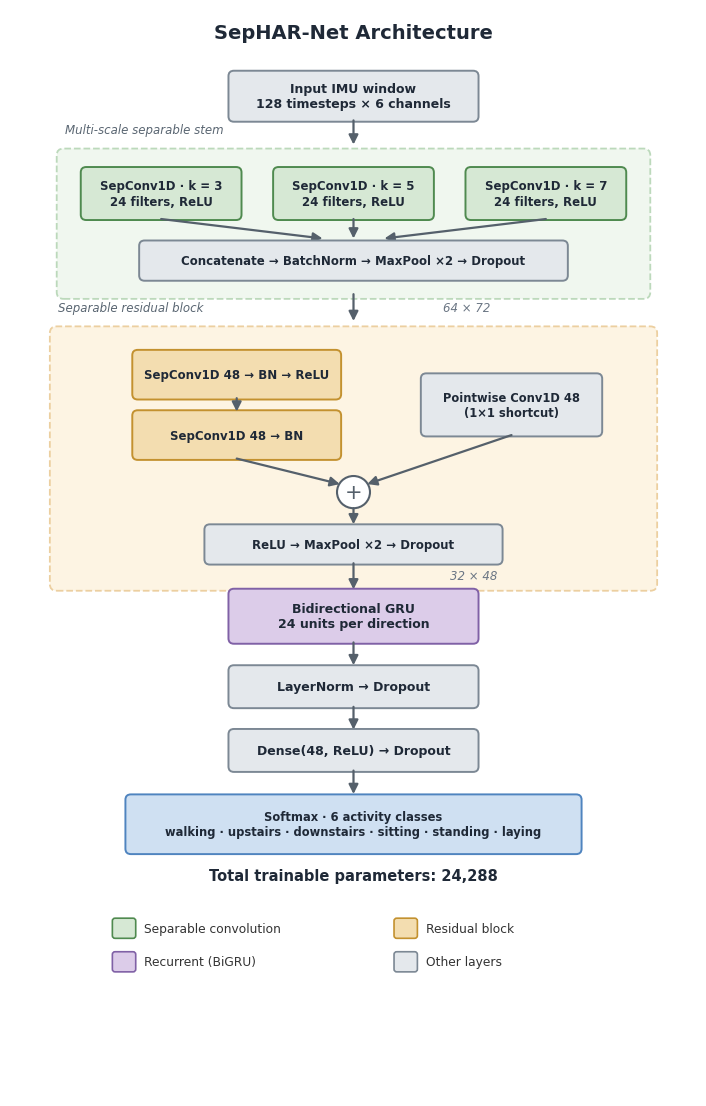

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
plt.rcParams.update({"font.family": "DejaVu Sans"})

GREEN=("#d6e8d4","#4f8a4f"); ORANGE=("#f3ddb0","#c3912f")
PURPLE=("#dccce9","#8061a6"); GREY=("#e4e8ec","#7c8894")
BLUE=("#cfe0f2","#4f84bf"); GROUPG=("#f0f7ef","#bcd9bb"); GROUPO=("#fdf4e3","#eccfa0")

fig, ax = plt.subplots(figsize=(7.2, 11.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 16.2); ax.axis("off")

def box(cx, cy, w, h, text, pal, fs=9.5, bold=True):
    fc, ec = pal
    ax.add_patch(FancyBboxPatch((cx-w/2, cy-h/2), w, h,
        boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.4))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs,
            color="#1f2937", fontweight="bold" if bold else "normal", linespacing=1.25)

def group(cx, cy, w, h, title, pal):
    fc, ec = pal
    ax.add_patch(FancyBboxPatch((cx-w/2, cy-h/2), w, h,
        boxstyle="round,pad=0.02,rounding_size=0.1", fc=fc, ec=ec, lw=1.3, ls="--"))
    # ax.text(cx-w/2+0.15, cy+h/2-0.26, title, ha="left", va="center",
         #   fontsize=8.5, style="italic", color="#5a6672")
    ax.text(cx-w/2+0.1, cy+h/2+0.2, title, ha="left", va="bottom",
            fontsize=8.5, style="italic", color="#5a6672")

def arrow(x1, y1, x2, y2, lw=1.6):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
        mutation_scale=14, lw=lw, color="#55606b", shrinkA=0, shrinkB=0))

def shape(cx, cy, txt):
    ax.text(cx, cy, txt, ha="center", va="center", fontsize=8.5,
            style="italic", color="#6b7684")

ax.text(5, 15.85, "SepHAR-Net Architecture", ha="center", va="center",
        fontsize=14, fontweight="bold", color="#1f2937")

box(5, 14.9, 3.6, 0.72, "Input IMU window\n128 timesteps \u00d7 6 channels", GREY, fs=9)
arrow(5, 14.54, 5, 14.18)

group(5, 13.0, 8.6, 2.2, "Multi-scale separable stem", GROUPG)
box(2.2, 13.45, 2.3, 0.75, "SepConv1D \u00b7 k = 3\n24 filters, ReLU", GREEN, fs=8.5)
box(5.0, 13.45, 2.3, 0.75, "SepConv1D \u00b7 k = 5\n24 filters, ReLU", GREEN, fs=8.5)
box(7.8, 13.45, 2.3, 0.75, "SepConv1D \u00b7 k = 7\n24 filters, ReLU", GREEN, fs=8.5)
for sx in (2.2, 7.8):
    arrow(sx, 13.07, 4.55 if sx < 5 else 5.45, 12.78)
arrow(5.0, 13.07, 5.0, 12.78)
box(5, 12.45, 6.2, 0.56, "Concatenate \u2192 BatchNorm \u2192 MaxPool \u00d72 \u2192 Dropout", GREY, fs=8.5)
arrow(5, 11.95, 5, 11.55); shape(6.65, 11.75, "64 \u00d7 72")

group(5, 9.5, 8.8, 3.9, "Separable residual block", GROUPO)
box(3.3, 10.75, 3.0, 0.7, "SepConv1D 48 \u2192 BN \u2192 ReLU", ORANGE, fs=8.5)
box(3.3, 9.85, 3.0, 0.7, "SepConv1D 48 \u2192 BN", ORANGE, fs=8.5)
box(7.3, 10.30, 2.6, 0.9, "Pointwise Conv1D 48\n(1\u00d71 shortcut)", GREY, fs=8.3)
arrow(3.3, 10.40, 3.3, 10.20)
ax.add_patch(Circle((5.0, 9.0), 0.24, fc="#ffffff", ec="#55606b", lw=1.5))
ax.text(5.0, 9.0, "+", ha="center", va="center", fontsize=15, color="#55606b")
arrow(3.3, 9.50, 4.80, 9.12)
arrow(7.3, 9.85, 5.20, 9.12)
arrow(5.0, 8.76, 5.0, 8.52)
box(5.0, 8.22, 4.3, 0.56, "ReLU \u2192 MaxPool \u00d72 \u2192 Dropout", GREY, fs=8.5)
arrow(5, 7.94, 5, 7.55); shape(6.75, 7.75, "32 \u00d7 48")

box(5, 7.15, 3.6, 0.78, "Bidirectional GRU\n24 units per direction", PURPLE, fs=9)
arrow(5, 6.76, 5, 6.42)
box(5, 6.1, 3.6, 0.6, "LayerNorm \u2192 Dropout", GREY, fs=9)
arrow(5, 5.8, 5, 5.46)
box(5, 5.15, 3.6, 0.6, "Dense(48, ReLU) \u2192 Dropout", GREY, fs=9)
arrow(5, 4.85, 5, 4.5)
# box(5, 4.05, 5.0, 0.85,
 #   "Softmax \u00b7 6 activity classes\nwalking \u00b7 upstairs \u00b7 downstairs \u00b7 sitting \u00b7 standing \u00b7 laying",
 #   BLUE, fs=8.3)
box(5, 4.05, 6.6, 0.85,
    "Softmax \u00b7 6 activity classes\nwalking \u00b7 upstairs \u00b7 downstairs \u00b7 sitting \u00b7 standing \u00b7 laying",
    BLUE, fs=8.3)
ax.text(5, 3.28, "Total trainable parameters: 24,288", ha="center", va="center",
        fontsize=10.5, fontweight="bold", color="#1f2937")

leg = [("Separable convolution", GREEN), ("Residual block", ORANGE),
       ("Recurrent (BiGRU)", PURPLE), ("Other layers", GREY)]
lx = [1.5, 5.6, 1.5, 5.6]; ly = [2.5, 2.5, 2.0, 2.0]
for (lab, pal), x, y in zip(leg, lx, ly):
    ax.add_patch(FancyBboxPatch((x, y-0.14), 0.32, 0.28,
        boxstyle="round,pad=0.01,rounding_size=0.04", fc=pal[0], ec=pal[1], lw=1.2))
    ax.text(x+0.45, y, lab, ha="left", va="center", fontsize=8.8, color="#333")

plt.tight_layout()
plt.savefig("Fig1.png", dpi=300, bbox_inches="tight")
plt.savefig("Fig1.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"}, bbox_inches="tight")
plt.show()


### 6.2 Fig 2 — UCI HAR LOSO accuracy

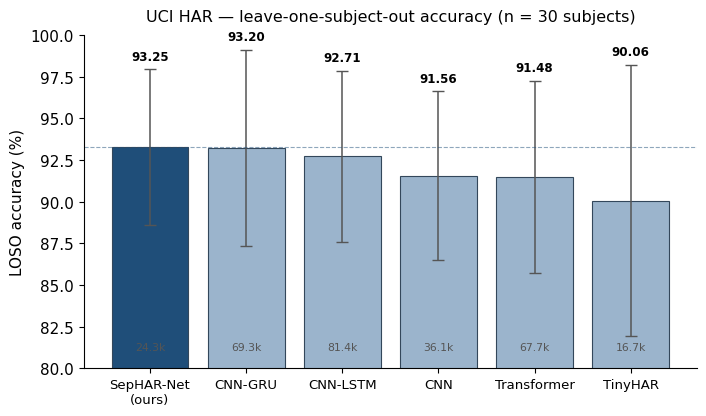

In [ ]:
order  = sorted(uci, key=lambda m: -uci[m]["mean"])
means  = [uci[m]["mean"] for m in order]
stds   = [uci[m]["std"]  for m in order]
colors = [HL if m == "SepHAR-Net" else GREY for m in order]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(7.2, 4.3))
ax.bar(x, means, yerr=stds, capsize=4, color=colors, edgecolor=EDGE,
       linewidth=0.8, error_kw=dict(ecolor="#555", lw=1.1))
ax.set_xticks(x); ax.set_xticklabels([DISP[m] for m in order], fontsize=9.5)
ax.set_ylabel("LOSO accuracy (%)"); ax.set_ylim(80, 100)
ax.set_title("UCI HAR — leave-one-subject-out accuracy (n = 30 subjects)", fontsize=11.5, pad=10)
for xi, m, s, mdl in zip(x, means, stds, order):
    ax.text(xi, m + s + 0.4, f"{m:.2f}", ha="center", va="bottom", fontsize=8.6, fontweight="bold")
    ax.text(xi, 81.0, f"{PARAMS[mdl]/1000:.1f}k", ha="center", va="bottom", fontsize=7.8, color="#555")
ax.axhline(means[0], ls="--", lw=0.8, color=HL, alpha=0.5)
plt.tight_layout(); plt.savefig("Fig2.png", dpi=300); plt.show()


### 6.3 Fig 3 — accuracy vs. model size

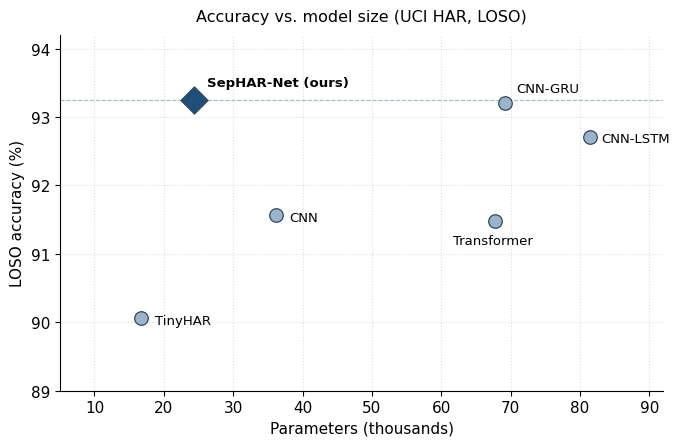

In [ ]:
offsets = {"SepHAR-Net": (10, 10), "CNN_GRU": (8, 8), "CNN_LSTM": (8, -4),
           "CNN": (10, -4), "Transformer": (-30, -16), "TinyHAR": (10, -4)}
fig, ax = plt.subplots(figsize=(7.0, 4.6))
for m in uci:
    ours = (m == "SepHAR-Net")
    ax.scatter(PARAMS[m]/1000, uci[m]["mean"], s=190 if ours else 95,
               marker="D" if ours else "o", color=HL if ours else GREY,
               edgecolor=EDGE, linewidth=0.9, zorder=3)
    ax.annotate(DISP[m].replace("\n", " "), (PARAMS[m]/1000, uci[m]["mean"]),
                textcoords="offset points", xytext=offsets.get(m, (8, 6)),
                fontsize=9.5, fontweight="bold" if ours else "normal")
ax.set_xlabel("Parameters (thousands)"); ax.set_ylabel("LOSO accuracy (%)")
ax.set_title("Accuracy vs. model size (UCI HAR, LOSO)", fontsize=11.5, pad=10)
ax.set_ylim(89, 94.2); ax.set_xlim(5, 92); ax.grid(ls=":", alpha=0.4)
ax.axhline(uci["SepHAR-Net"]["mean"], ls="--", lw=0.8, color=HL, alpha=0.4)
plt.tight_layout(); plt.savefig("Fig3.png", dpi=300); plt.show()


### 6.4 Fig 4 — MotionSense LOSO accuracy

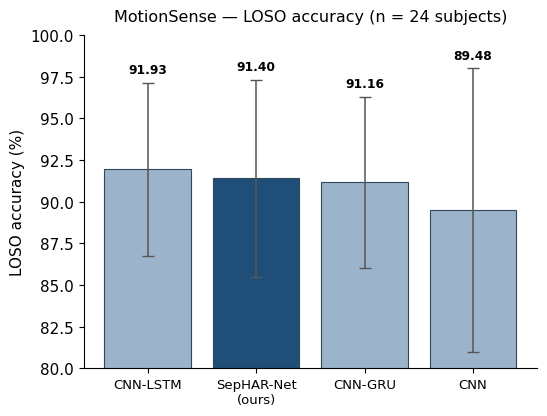

In [ ]:
order  = sorted(ms, key=lambda m: -ms[m]["mean"])
means  = [ms[m]["mean"] for m in order]
stds   = [ms[m]["std"]  for m in order]
colors = [HL if m == "SepHAR-Net" else GREY for m in order]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(5.6, 4.3))
ax.bar(x, means, yerr=stds, capsize=4, color=colors, edgecolor=EDGE,
       linewidth=0.8, error_kw=dict(ecolor="#555", lw=1.1))
ax.set_xticks(x); ax.set_xticklabels([DISP[m] for m in order], fontsize=9.5)
ax.set_ylabel("LOSO accuracy (%)"); ax.set_ylim(80, 100)
ax.set_title("MotionSense — LOSO accuracy (n = 24 subjects)", fontsize=11.5, pad=10)
for xi, m, s in zip(x, means, stds):
    ax.text(xi, m + s + 0.4, f"{m:.2f}", ha="center", va="bottom", fontsize=8.8, fontweight="bold")
plt.tight_layout(); plt.savefig("Fig4.png", dpi=300); plt.show()


### 6.5 Fig 5 — confusion matrix

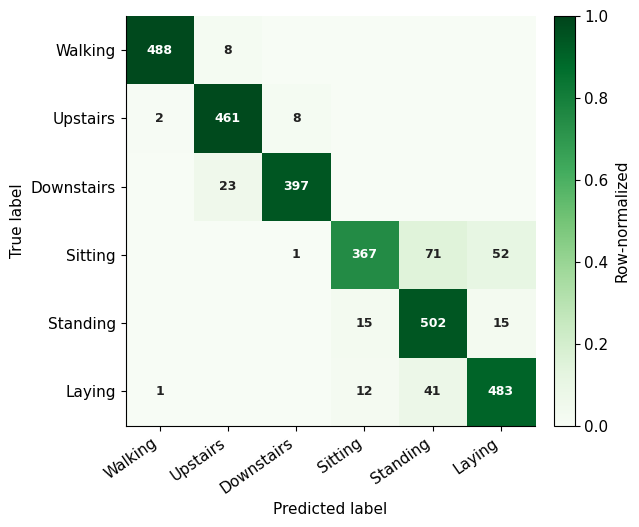

In [ ]:
import numpy as np, matplotlib.pyplot as plt

# Confusion-matrix counts from the representative SepHAR-Net run (seed 42, UCI HAR test set).
# These are from your fixed-split analysis. If you have a live run, you can instead use:
#   from sklearn.metrics import confusion_matrix;  cm = confusion_matrix(y_test, y_pred)
labels = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]
cm = np.array([
    [488,   8,   0,   0,   0,   0],
    [  2, 461,   8,   0,   0,   0],
    [  0,  23, 397,   0,   0,   0],
    [  0,   0,   1, 367,  71,  52],
    [  0,   0,   0,  15, 502,  15],
    [  1,   0,   0,  12,  41, 483],
])
cmn = cm / cm.sum(axis=1, keepdims=True)          # row-normalized for shading

fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(cmn, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(6)); ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
for i in range(6):
    for j in range(6):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "#222", fontsize=9, fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Row-normalized")
plt.tight_layout()
plt.savefig("Fig5.png", dpi=300)
plt.savefig("Fig5.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
plt.show()


### 6.6 Fig 6 — seed stability

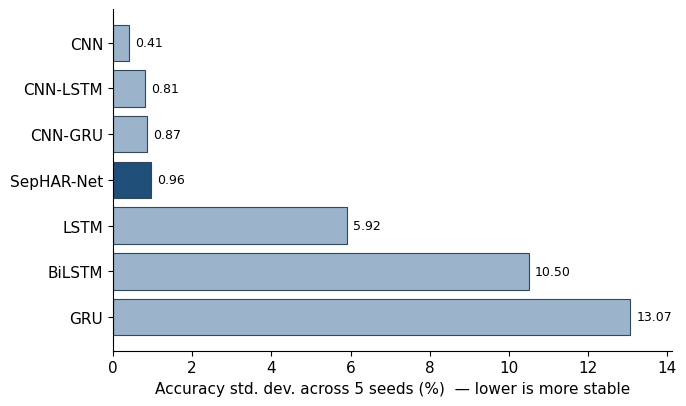

In [ ]:
import numpy as np, matplotlib.pyplot as plt

# Std of test accuracy across 5 seeds (fixed split) — from the secondary-analysis table.
std = {"CNN": 0.41, "CNN-LSTM": 0.81, "CNN-GRU": 0.87, "SepHAR-Net": 0.96,
       "LSTM": 5.92, "BiLSTM": 10.50, "GRU": 13.07}
order  = sorted(std, key=lambda m: std[m])        # most stable first
vals   = [std[m] for m in order]
colors = ["#1f4e79" if m == "SepHAR-Net" else "#9bb4cc" for m in order]

fig, ax = plt.subplots(figsize=(7.0, 4.2))
y = np.arange(len(order))
ax.barh(y, vals, color=colors, edgecolor="#33475b", linewidth=0.8)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("Accuracy std. dev. across 5 seeds (%)  \u2014 lower is more stable")
for yi, v in zip(y, vals):
    ax.text(v + 0.15, yi, f"{v:.2f}", va="center", fontsize=9)
ax.margins(x=0.08)
plt.tight_layout()
plt.savefig("Fig6.png", dpi=300)
plt.savefig("Fig6.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
plt.show()


### 6.7 Export figures to TIFF and download

In [ ]:
from PIL import Image
import os
for f in sorted(x for x in os.listdir(".") if x.startswith("Fig") and x.endswith(".png")):
    out = f.replace(".png", ".tif")
    Image.open(f).convert("RGB").save(out, compression="tiff_lzw", dpi=(300, 300))
    print("saved", out)


saved Fig1.tif
saved Fig2.tif
saved Fig3.tif
saved Fig4.tif
saved Fig5.tif
saved Fig6.tif


In [ ]:
from google.colab import files
for n in [1, 2, 3, 4, 5, 6]:
    files.download(f"Fig{n}.tif")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>